Today's topics:
* outliers and a least-squares line
* mean absolute error as an objective for `minimize`
* selecting rows to refit

# Titanium alloys

Titanium alloys go into jet engines, bicycle frames, and hip implants.

Today we will fit a line to a table of their strengths.
A few alloys sit far from that line.

*Which alloys are they, and what should we do about them?*

<img src="https://upload.wikimedia.org/wikipedia/commons/6/6f/Al_tensile_test.jpg" alt="An aluminum alloy tensile specimen broken in two, with visible necking near the break and a cup and cone fracture surface" width=300/> <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/4/4f/Compression_test-Universal_testing_machine.jpg/960px-Compression_test-Universal_testing_machine.jpg" alt="A cylindrical specimen sitting between the two flat steel platens of a universal testing machine, with the load cell above and a control panel to the side" width=300/>

*Left: photo by Sigmund, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Al_tensile_test.jpg).*

*Right: photo by Cjp24, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Compression_test-Universal_testing_machine.jpg).*

Above: a [tensile test](https://en.wikipedia.org/wiki/Tensile_testing) taken to fracture, and a [compression test](https://en.wikipedia.org/wiki/Compression_test) in a universal testing machine.

Two kinds of test show up in our table:
* In a **tension** test, the specimen is pulled apart.
* In a **compression** test, the specimen is pressed between two platens.

The highest stress in a tension test is the ultimate tensile strength (UTS).
The highest stress in a compression test is the maximum compressive strength.

The table stores both in the column `UTS_MPa`, and labels each row in `test_mode`.
That makes `UTS_MPa` a **mixed strength field**, and `YS_MPa` mixes tension and compression yield stresses in the same way.

The data are from [Salvador et al., *Scientific Data* 9, 188](https://doi.org/10.1038/s41597-022-01283-9) (CC BY 4.0).

Let's fit a line to all 190 complete rows, then look at the alloys far above it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/biomaterials_ti_alloys.csv')
both = data.dropna(subset=['YS_MPa', 'UTS_MPa'])
x = both['YS_MPa']
y = both['UTS_MPa']

fit = stats.linregress(x, y)
residuals = y - (fit.slope * x + fit.intercept)
print(len(both), 'alloys')

190 alloys


For a first look, let's use a mask to pick out the alloys more than 400 MPa above the line.

In [2]:
far = residuals > 400
print(both.loc[far, ['eid', 'YS_MPa', 'UTS_MPa', 'test_mode']])

                 eid  YS_MPa  UTS_MPa    test_mode
98       TiZr-5Al-3V   690.0   1355.0      tension
129  Ti-33Zr-3Fe-2Cr  1049.0   1755.0  compression
130  Ti-33Zr-5Fe-2Cr  1130.0   1830.0  compression
131  Ti-33Zr-7Fe-2Cr  1239.0   1901.0  compression
132  Ti-33Zr-3Fe-4Cr  1113.0   2008.0  compression
146  Ti-15Zr-5Cr-2Al   625.4   1879.9  compression
155   Ti-8.5Cr-1.5Sn   554.0   1240.0      tension
279   at_Ti-20Fe-5Sn  1700.0   2332.0  compression


Most of the labels are `compression`.
How many compression rows are in the whole table?

In [3]:
print(np.sum(both['test_mode'] == 'compression'), 'compression rows')
print(np.sum(both['test_mode'] == 'tension'), 'tension rows')

16 compression rows
166 tension rows


Let's isolate the effect of one bad value in a small example where we know the right answer.

*How far can one wrong reading move a fitted line?*

# One bad value in a least-squares fit

Vickers hardness (HV) and yield strength are roughly proportional in many metals.

Here are seven specimens of a steel, each with a hardness reading and a measured yield strength.
These are teaching data, constructed for today.

The record at HV 240 contains 7850 MPa, an extra digit on a true value of 785 MPa.

In [4]:
hv = np.array([120, 150, 180, 210, 240, 270, 300])                # Vickers hardness
yield_clean = np.array([395, 490, 590, 690, 785, 885, 980])       # MPa
yield_typo = np.array([395, 490, 590, 690, 7850, 885, 980])       # MPa, extra digit at HV 240

Let's fit a line to the clean and the mistyped arrays with `stats.linregress`.

In [5]:
fit_clean = stats.linregress(hv, yield_clean)
fit_typo = stats.linregress(hv, yield_typo)

print(f'clean data: slope = {fit_clean.slope:.2f} MPa per HV')
print(f'typo data:  slope = {fit_typo.slope:.2f} MPa per HV')

clean data: slope = 3.26 MPa per HV
typo data:  slope = 11.67 MPa per HV


Let's plot both lines on the data.

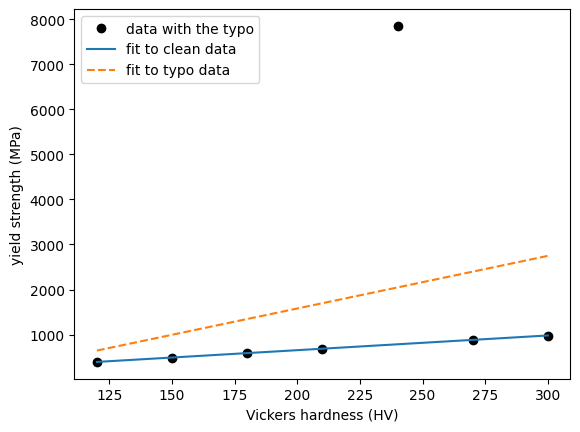

In [6]:
fig, ax = plt.subplots()
ax.plot(hv, yield_typo, 'o', color='black', label='data with the typo')
ax.plot(hv, fit_clean.slope * hv + fit_clean.intercept, '-', label='fit to clean data')
ax.plot(hv, fit_typo.slope * hv + fit_typo.intercept, '--', label='fit to typo data')
ax.set_xlabel('Vickers hardness (HV)')
ax.set_ylabel('yield strength (MPa)')
ax.legend()

One point out of seven tilts the fitted line a long way, so it no longer runs through the other six.

Least squares adds up the squared residuals, so a large residual dominates the sum.
Let's compute each point's share of that sum.

In [7]:
resid_typo = yield_typo - (fit_typo.slope * hv + fit_typo.intercept)
share = resid_typo**2 / np.sum(resid_typo**2)

print(f'point at HV 240 accounts for {100 * share[4]:.0f}% of the sum of squared residuals')

point at HV 240 accounts for 82% of the sum of squared residuals


# Mean absolute error as an objective

In L13 we computed the mean absolute error (MAE) as a number after the fit.

A residual of size $r$ adds $r^2$ to the sum of squares and $|r|$ to the MAE.
Let's minimize the MAE instead.

A residual ten times larger adds ten times as much to the MAE and a hundred times as much to the sum of squares.

The objective is the same recipe as `sse_decay` from Lecture 22, with one change.
We return the mean absolute residual.

In [8]:
def mae_line(params):
    m, b = params
    residuals = yield_typo - (m * hv + b)
    return np.mean(np.abs(residuals))

> Recipe: for an absolute-value objective we add `method='Nelder-Mead'` to the call.
> It's a different solver, one that works with the corner of an absolute value.
> We copy and run it as it is, and nobody has to write it from memory.

In [9]:
res_mae = optimize.minimize(mae_line, [1, 1], method='Nelder-Mead')
print(res_mae.x, res_mae.success)

[3.26666724 2.99982719] True


Let's compare the three slopes.

In [10]:
m_mae, b_mae = res_mae.x

print(f'least squares, clean data: {fit_clean.slope:.2f} MPa per HV')
print(f'least squares, typo data:  {fit_typo.slope:.2f} MPa per HV')
print(f'minimum MAE, typo data:    {m_mae:.2f} MPa per HV')

least squares, clean data: 3.26 MPa per HV
least squares, typo data:  11.67 MPa per HV
minimum MAE, typo data:    3.27 MPa per HV


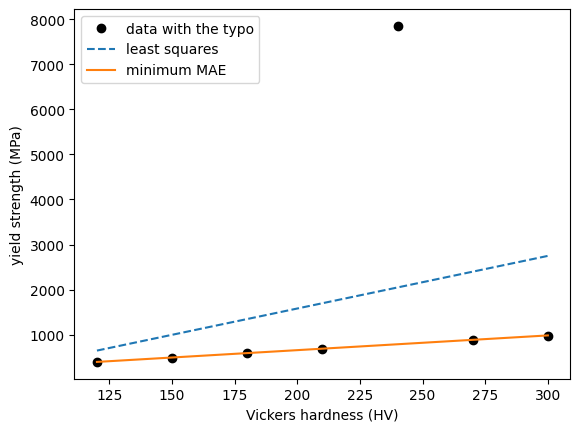

In [11]:
fig, ax = plt.subplots()
ax.plot(hv, yield_typo, 'o', color='black', label='data with the typo')
ax.plot(hv, fit_typo.slope * hv + fit_typo.intercept, '--', label='least squares')
ax.plot(hv, m_mae * hv + b_mae, '-', label='minimum MAE')
ax.set_xlabel('Vickers hardness (HV)')
ax.set_ylabel('yield strength (MPa)')
ax.legend()

The minimum-MAE line stays close to the six good readings and passes far from the typo.
Its slope is close to the slope of the clean data.

### [Check your understanding]

Let's make the typo bigger and bigger.
Here is a loop that rebuilds `yield_typo` before each fit, so `mae_line` reads the new array.

```
bad_values = [785, 1500, 3000, 7850]
for bad in bad_values:
    yield_typo = np.array([395, 490, 590, 690, bad, 885, 980])
    ls_slope = ...
    res = optimize.minimize(mae_line, [1, 1], method='Nelder-Mead')
    mae_slope = ...
    print(bad, ls_slope, mae_slope)
```

1. Copy the loop into a cell and replace each `...`.
   - `ls_slope` is the slope from `stats.linregress(hv, yield_typo)`.
   - `mae_slope` is the first entry of `res.x`.
2. Which slope changes strongly as `bad` grows, and which changes very little?

**Optional challenge:**
- At `bad = 785` there is no typo. How close are the two slopes?
- A reviewer says the least-squares slope is the slope of the calibration. Using your printed table, what does one wrong reading do to that claim?
- Put `bad` at HV 120 instead of HV 240 and repeat.

# Fitting the alloy table

Now let's fit all 190 alloys by least squares and by minimum MAE.

The MAE objective is the same recipe with `x` and `y` from the table.
We start at a slope of 1 and an intercept of 100 MPa.

In [12]:
def mae_alloys(params):
    m, b = params
    residuals = y - (m * x + b)
    return np.mean(np.abs(residuals))

res_alloys = optimize.minimize(mae_alloys, [1, 100], method='Nelder-Mead')
m_alloys, b_alloys = res_alloys.x
print(f'slope = {m_alloys:.3f}, intercept = {b_alloys:.0f} MPa, success = {res_alloys.success}')

slope = 0.828, intercept = 251 MPa, success = True


Each line gets two scores from its own residuals: the RMSE and the MAE.

In [13]:
resid_ls = residuals
resid_mae = y - (m_alloys * x + b_alloys)

print('                 RMSE (MPa)   MAE (MPa)')
print(f'least squares    {np.sqrt(np.mean(resid_ls**2)):8.1f}   {np.mean(np.abs(resid_ls)):8.1f}')
print(f'minimum MAE      {np.sqrt(np.mean(resid_mae**2)):8.1f}   {np.mean(np.abs(resid_mae)):8.1f}')

                 RMSE (MPa)   MAE (MPa)
least squares       181.1      129.9
minimum MAE         198.0      117.9


Each line has the lowest value of the score it was fitted to.

Now let's plot them, with the compression rows in orange.

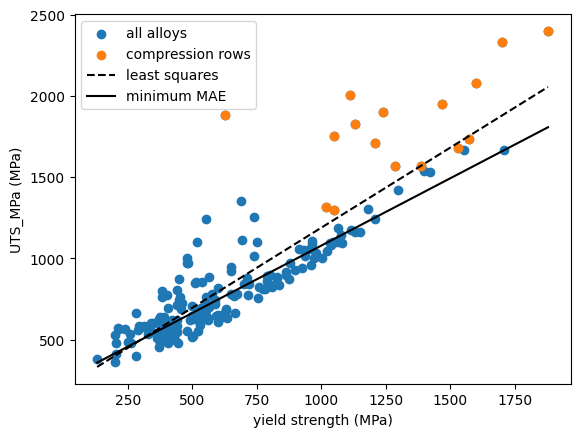

In [14]:
comp = both.loc[both['test_mode'] == 'compression']
x_line = np.array([np.min(x), np.max(x)])

fig, ax = plt.subplots()
ax.scatter(x, y, label='all alloys')
ax.scatter(comp['YS_MPa'], comp['UTS_MPa'], color='tab:orange', label='compression rows')
ax.plot(x_line, fit.slope * x_line + fit.intercept, '--', color='black', label='least squares')
ax.plot(x_line, m_alloys * x_line + b_alloys, '-', color='black', label='minimum MAE')
ax.set_xlabel('yield strength (MPa)')
ax.set_ylabel('UTS_MPa (MPa)')
ax.legend()

The compression rows sit in the upper part of the cloud, and the minimum-MAE line lies lower than the least-squares line.

We can compare the residuals of each group.
We take the median, since a few large residuals would move a mean.

In [15]:
is_comp = both['test_mode'] == 'compression'
is_tens = both['test_mode'] == 'tension'

print('median residual (MPa)    least squares   minimum MAE')
print(f'compression rows         {np.median(resid_ls.loc[is_comp]):10.0f}   {np.median(resid_mae.loc[is_comp]):10.0f}')
print(f'tension rows             {np.median(resid_ls.loc[is_tens]):10.0f}   {np.median(resid_mae.loc[is_tens]):10.0f}')

median residual (MPa)    least squares   minimum MAE
compression rows                308          493
tension rows                    -66          -11


Let's refit using only the tension rows.
The objective for those rows reads `tension` when it's called.

In [16]:
def mae_tension(params):
    m, b = params
    residuals = tension['UTS_MPa'] - (m * tension['YS_MPa'] + b)
    return np.mean(np.abs(residuals))

### [Check your understanding]

1. Build `tension = both.loc[both['test_mode'] == 'tension']` and print `len(tension)`.
   Eight rows in the table have no `test_mode` label, so they are not in `tension`.
2. Fit the tension rows both ways and print the two slopes.
   - Print the slope of `stats.linregress(tension['YS_MPa'], tension['UTS_MPa'])`.
   - Call `optimize.minimize(mae_tension, [1, 100], method='Nelder-Mead')` and print the first entry of `res.x`.

**Optional challenge:**
- In a comment, say which population each line describes and which one we'd report for a tensile-strength question.
- The compression rows are real measurements of a different quantity. Would you remove them, keep them in one fit, or fit the tension rows only? Give one reason.
- Plot the tension rows with their two lines.

# Remove, keep, or separate

When a point sits far from a line, we have a decision to make.

Three answers come up often, and each one is a judgement about the material:
* **Remove or correct** a recording error when the lab record supports the change.
  For the constructed 7850 MPa value, we defined 785 MPa as the correct one.
* **Keep** a real extreme after we check its source, units, test mode, comments, and physical plausibility.
* **Separate** rows that measure a different quantity from the one we're fitting.
  The compression rows are valid measurements: `UTS_MPa` holds maximum compressive strength for them and ultimate tensile strength for the tension rows.

For a tensile-strength question, I'd fit the tension rows.

We decide by asking three questions:
* Can we name a physical or procedural reason for the point?
* Does removing it change the question we can answer?
* Can we defend the choice in one sentence in a report?

A larger $R^2$ is not a reason to drop a point.

# Summary

On outliers and least squares:
* Least squares sums the squared residuals, so one wrong value can move the fitted slope a long way.

On mean absolute error:
* MAE is the average size of the misses, and `np.mean(np.abs(residuals))` makes it the objective inside a `minimize` function.
* For an absolute-value objective we copy `method='Nelder-Mead'` into the `minimize` call.
* Each line has the lowest score of the kind it was fitted to: the least-squares line has the lower RMSE, and the minimum-MAE line has the lower MAE.

On the titanium alloys:
* Most of the alloys far above the line are compression tests, and `UTS_MPa` is a mixed strength field.
* For a point far from a fit we choose to remove it, keep it, or fit the rows separately, and we write down the reason.

## Further reading

* Kong, Siauw, and Bayen, *Python Programming and Numerical Methods*, [Chapter 16, "Least Squares Regression"](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter16.00-Least-Squares-Regression.html)
* [`scipy.optimize.minimize` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html), which lists the methods including Nelder-Mead
* Salvador, C. A. F. et al. "A compilation of experimental data on the mechanical properties and microstructural features of Ti-alloys." *Scientific Data* 9, 188 (2022). https://doi.org/10.1038/s41597-022-01283-9
* Photo credit: aluminum tensile test, Sigmund, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/), [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Al_tensile_test.jpg)
* Photo credit: compression test, Cjp24, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0), [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Compression_test-Universal_testing_machine.jpg)

# Appendix A: A fence on the residuals

Optional.

Percentiles and the interquartile range (IQR) describe the middle and spread of the residuals.

A **fence** at $Q_3 + 1.5\,\mathrm{IQR}$ flags residuals far above the middle of the group.
The 1.5 is a convention, and 3 is a common stricter choice.

In [17]:
q1, q3 = np.percentile(residuals, [25, 75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr
print(f'fence: {lower:.0f} to {upper:.0f} MPa')

above = residuals > upper
below = residuals < lower
print(np.sum(above), 'above the fence,', np.sum(below), 'below it')

fence: -429 to 372 MPa
9 above the fence, 0 below it


In [18]:
print(both.loc[above, ['eid', 'test_mode']])

                 eid    test_mode
98       TiZr-5Al-3V      tension
129  Ti-33Zr-3Fe-2Cr  compression
130  Ti-33Zr-5Fe-2Cr  compression
131  Ti-33Zr-7Fe-2Cr  compression
132  Ti-33Zr-3Fe-4Cr  compression
146  Ti-15Zr-5Cr-2Al  compression
155   Ti-8.5Cr-1.5Sn      tension
156        Ti-9Mo-6W      tension
279   at_Ti-20Fe-5Sn  compression


# Appendix B: Check your understanding

Optional.
Let's put the fence on the residuals of the minimum-MAE line.

1. Compute the upper fence of `resid_mae` with `np.percentile`, and store the mask as `above_mae`.
2. Count the residuals above the fence, and count how many of those rows have `test_mode == 'compression'`.
   Use `np.sum(above_mae)` for the first count and `both.loc[above_mae, 'test_mode']` for the second.
3. Which fit has more residuals above its fence?
   Compare the median compression-row residual under the two fits.

*What changed about the residuals of the compression rows?*

# Appendix C: A z-score rule

Optional.
The **z-score** of a residual is its distance from the mean in standard deviations.
A common rule flags $|z| > 3$.

In [19]:
z = (residuals - np.mean(residuals)) / np.std(residuals)
print(np.sum(np.abs(z) > 3), 'rows with |z| > 3')

2 rows with |z| > 3


The mean and the standard deviation both change when an outlier is added, like the slope did in the steel example.
The fence in Appendix A uses percentiles, which move less.